In [5]:
import math
from pathlib import Path

import cv2
import numpy as np
import torch
from IPython.display import Markdown, display
from PIL import Image

FIBONACCI_PATH = Path('./outputs/studio_small_09_fibonacci.npz')
REFERENCE_ERP_PATH = Path('./dataset/studio_small_09_1k.hdr')
OUTPUT_HDR_PATH = Path('./outputs/studio_small_09_erp_from_fibonacci.hdr')
ERP_HEIGHT = 512
NUM_NEIGHBORS = 4
BATCH_INDEX = 0
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [2]:
def fibonacci_to_erp(directions, rgb, height, num_neighbors=4):
    """Interpolate [N, 3] directions and [B, N, 3] colors to [B, 3, H, 2H]."""
    if directions.ndim != 2 or directions.shape[1] != 3 or directions.shape[0] < 1:
        raise ValueError('Expected nonempty directions with shape [N, 3]')
    num_samples = directions.shape[0]
    if rgb.ndim != 3 or rgb.shape[0] < 1 or rgb.shape[1:] != (num_samples, 3):
        raise ValueError('Expected RGB with shape [B, N, 3] matching the directions')
    if directions.dtype not in (torch.float32, torch.float64) or rgb.dtype != directions.dtype:
        raise TypeError('Directions and RGB must use the same float32 or float64 dtype')
    if directions.device != rgb.device:
        raise ValueError('Directions and RGB must be on the same device')
    if not isinstance(height, int) or isinstance(height, bool) or height < 1:
        raise ValueError('ERP height must be a positive integer')
    if not isinstance(num_neighbors, int) or isinstance(num_neighbors, bool) or num_neighbors < 1:
        raise ValueError('num_neighbors must be a positive integer')
    norms = directions.norm(dim=-1, keepdim=True)
    if not torch.isfinite(directions).all() or not torch.isfinite(rgb).all():
        raise ValueError('Directions and RGB must contain finite values')
    if not torch.allclose(norms, torch.ones_like(norms), atol=1e-5, rtol=0):
        raise ValueError('Expected unit directions')
    directions = directions / norms

    width = 2 * height
    options = {'device': directions.device, 'dtype': directions.dtype}
    longitude = ((torch.arange(width, **options) + 0.5) / width - 0.5) * (2 * math.pi)
    latitude = (0.5 - (torch.arange(height, **options) + 0.5) / height) * math.pi
    phi, theta = torch.meshgrid(latitude, longitude, indexing='ij')
    cos_phi = phi.cos()
    queries = torch.stack((cos_phi * theta.sin(), phi.sin(), cos_phi * theta.cos()), dim=-1)
    queries = queries.reshape(-1, 3)

    neighbors = min(num_neighbors, num_samples)
    # Limit the size of the temporary pixel-by-sample similarity matrix.
    pixels_per_chunk = max(1, (4 * 1024 * 1024) // num_samples)
    erp_pixels = rgb.new_empty(rgb.shape[0], len(queries), 3)
    for start in range(0, len(queries), pixels_per_chunk):
        chunk = queries[start:start + pixels_per_chunk]
        indices = (chunk @ directions.T).topk(neighbors, dim=-1).indices
        offsets = chunk[:, None, :] - directions[indices]
        distance_squared = offsets.square().sum(dim=-1)
        exact = distance_squared == 0
        weights = distance_squared.clamp_min(torch.finfo(directions.dtype).eps ** 2).reciprocal()
        weights = torch.where(exact.any(dim=-1, keepdim=True), exact.to(weights.dtype), weights)
        weights = weights / weights.sum(dim=-1, keepdim=True)
        erp_pixels[:, start:start + len(chunk)] = (rgb[:, indices] * weights[..., None]).sum(dim=2)

    return erp_pixels.reshape(rgb.shape[0], height, width, 3).permute(0, 3, 1, 2).contiguous()

In [7]:
with np.load(FIBONACCI_PATH, allow_pickle=False) as samples:
    directions = torch.from_numpy(samples['directions']).to(DEVICE)
    rgb = torch.from_numpy(samples['rgb']).to(DEVICE)

erp = fibonacci_to_erp(directions, rgb, ERP_HEIGHT, NUM_NEIGHBORS)
pixels = erp[BATCH_INDEX].permute(1, 2, 0).detach().cpu().numpy().astype(np.float32)
print('Samples:', tuple(directions.shape), 'RGB:', tuple(rgb.shape))
print('ERP:', tuple(erp.shape), 'device:', erp.device)
print('Reconstructed HDR range:', (float(pixels.min()), float(pixels.max())))

Samples: (32768, 3) RGB: (1, 32768, 3)
ERP: (1, 3, 512, 1024) device: cuda:0
Reconstructed HDR range: (0.0011024242267012596, 324.58489990234375)


Saved HDR: E:\model\erpProcess\outputs\studio_small_09_erp_from_fibonacci.hdr
Saved PNG: E:\model\erpProcess\outputs\studio_small_09_erp_from_fibonacci.png


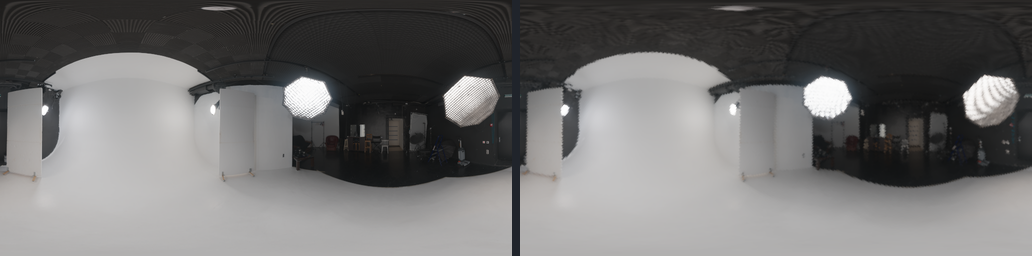

In [8]:
def hdr_preview(rgb):
    """Apply the same preview tone mapping used by fibonaccifromerp.ipynb."""
    rgb = np.maximum(rgb, 0)
    mapped = (rgb / (1 + rgb)) ** (1 / 2.2)
    return Image.fromarray(np.rint(mapped * 255).astype(np.uint8))


if pixels.min() < 0:
    raise ValueError('Radiance HDR requires nonnegative RGB values')
OUTPUT_HDR_PATH.parent.mkdir(parents=True, exist_ok=True)
if not cv2.imwrite(str(OUTPUT_HDR_PATH), cv2.cvtColor(pixels, cv2.COLOR_RGB2BGR)):
    raise OSError(f'Cannot write HDR image: {OUTPUT_HDR_PATH.resolve()}')
preview_path = OUTPUT_HDR_PATH.with_suffix('.png')
preview = hdr_preview(pixels)
preview.save(preview_path)
print('Saved HDR:', OUTPUT_HDR_PATH.resolve())
print('Saved PNG:', preview_path.resolve())

if REFERENCE_ERP_PATH is not None and REFERENCE_ERP_PATH.is_file():
    reference_bgr = cv2.imread(str(REFERENCE_ERP_PATH), cv2.IMREAD_UNCHANGED)
    if reference_bgr is None:
        raise OSError(f'Cannot read reference image: {REFERENCE_ERP_PATH.resolve()}')
    reference = hdr_preview(cv2.cvtColor(reference_bgr, cv2.COLOR_BGR2RGB))
    preview_size = (512, 256)
    comparison = Image.new('RGB', (2 * preview_size[0] + 8, preview_size[1]), '#20242b')
    comparison.paste(reference.resize(preview_size, Image.Resampling.LANCZOS), (0, 0))
    comparison.paste(preview.resize(preview_size, Image.Resampling.LANCZOS), (preview_size[0] + 8, 0))
    display(comparison)
else:
    display(preview)